# 1. EDA
- 데이터의 특징을 파악하는 방법
    1. 평균이나 분산 등의 수치 지표에 따라 데이터를 요약하는 방법
    2. 시각적으로 데이터를 파악하는 방법

# 1. 1차원 데이터

In [1]:
import numpy as np
import pandas as pd

df = pd.read_csv('./data/students_scores.csv', index_col='student number')

In [2]:
df.head()

,english,mathematics
student number,,
1,42,65
2,69,80
3,56,63
4,41,63
5,57,76


## 1.2 데이터 중심 지표
- 데이터 중심지표란
    - 데이터를 중심으로 나타내는 지표
    - 데이터를 하나의 값으로 요약한 지표
    - 대푯값
        - 평균값, 중앙값, 최빈값

## 1.2.1 평균

In [3]:
# pandas 활용
print(df['english'].mean())
print(df['mathematics'].mean())
print()
# numpy 활용
print(np.mean(df['english']))
print(np.mean(df['mathematics']))

58.38
78.88

58.38
78.88


## 1.2.2 중앙값
- 평균에 비해 이상치에 영향을 덜 받음

In [4]:
# numpy 활용
print(np.median(df['english']))

# pandas 활용
print(df['english'].median())

57.5
57.5


## 1.2.3 최빈값

In [5]:
temp = pd.Series([1,1,1,2,2,3,3,5,5,5,5,5,5,5])

In [6]:
temp.mode()

0    5
dtype: int64

## 1.3 데이터의 산포도 지표

- 산포도: 데이터가 평균에서 얼마나 흩어져있는지를 나타내는 정도 
- 종류: 범위(최대최소 차이), 분산, 표준편차, 사분위 범위
- 산포도를 구하는 이유
    - 대푯값의 한계를 보완
    - 평균이 같아도 자료의 흩어진 정도가 다르며, 산포도는 이 차이를 보여줄 수 있음 
    - 예: 평균 키가 같은 두 학급 비교 

### 1.3.1 편차(Deviation)

- 분산을 이해하기 위해 우선 편차를 이해해보자 
- 편차는 각 데이터가 평균으로부터 어느 정도 떨어져있는가를 나타내는 지표 
- 예: A학생의 점수가 42점이고, 학생 10명의 평균 점수가 55점이라면, A 학생의 편차는 42-55=-13이 됨

In [7]:
eng_scores = df['english']

eng_mean = np.mean(eng_scores)

eng_deviation = eng_scores - eng_mean

print(eng_mean)
print(eng_deviation.head())

58.38
student number
1   -16.38
2    10.62
3    -2.38
4   -17.38
5    -1.38
Name: english, dtype: float64


### 1.3.2 분산(Variance)

- 하지만 50명의 편차를 다른 학급 50명의 편차와 비교하는 것은 어렵기 때문에 하나의 값으로 정리하여 비교하고자 함 (편차의 대푯값 구하기) 
- 편차의 대푯값으로 편차의 평균을 생각할 수 있겠지만 편차의 평균은 항상 0이 되기때문에 평균은 대푯값으로 적절하지 않음 
- 만약 A학생은 편차가 -6이고 B학생은 6이라고 했을 때, 두 학생은 모두 평균에서 6점 떨어져있어서 동일한 정도의 산포도를 갖고있으므로 평균보다 6점이 크든 작든 둘을 동일하게 취급하기 위해 편차의 제곱을 이용하게 됨 
- 그리고 편차의 제곱의 평균으로 정의되는 지표를 **분산**이라고 함 

In [8]:
# 데이터를 모집단이라 가정할 때 -> numpy에서 제공하는 분산 함수 활용

eng_var_np = np.var(df['english'])
print(eng_var_np)


94.1156


In [14]:
# 데이터가 표본이라고 가정할 때 -> pandas의 dataframe or series에서 제공하는 분산 함수 활용

env_var_df = df['english'].var()

print(f'{env_var_df:.4f}')

96.0363


In [ ]:
print(eng_mean)
print(env_var_df)

# 분산을 구할 때 편차의 제곱으로 인해 단위가 달라짐
# 제곱근을 활용해 단위를 맞춰줌



58.38
96.03632653061224


### 1.3.3 표준편차

 - 원래 데이터와 동일한 단위를 쓰기 위해 분산에서 제곱근을 취한 형태

In [ ]:
eng_std_np = np.std(eng_scores)
eng_std_np

np.float64(9.70131949788275)

### 1.3.4 사분위 범위
- 범위: 데이터 전체를 보는 게 아닌, 초댓값과 최솟값으로만 판단하므로 이상값이 하나라도 있으면 범위도 크게 변하게 됨
- 분산과 표준편차는 평균에 대해 정의한다면, 사분위는 중앙값에 대해 정의되는 산포도의 지표임 
- 따라서 사분위는 이상치에 강하며 왜곡된 데이터에서 유용하게 쓰임
- 사분위 범위는 데이터를 오름차순으로 정렬하여 하위 25%, 50%(중앙값), 70%에 위치하는 값에 주목
- 사분위수(Quartile): 위의 구간을 각각 제 1사분위(Q1), 2사분위(Q2), 3사분위(Q3)라고 표현
- Q2는 중앙값과 일치
- IQR 공식: Q3 - Q1 (중앙 50%구간의 폭을 의미)

In [ ]:


print(eng_q1)
print(eng_q3)
print(eng_iqr)

54.0
65.0
11.0


In [20]:
df.describe()

,english,mathematics
count,50.000000,50.000000
mean,58.380000,78.880000
std,9.799813,8.414371
min,37.000000,57.000000
25%,54.000000,76.000000
50%,57.500000,80.000000
75%,65.000000,84.000000
max,79.000000,94.000000


## 1.4 데이터의 정규화 

- 시험 점수는 동일한 60점이더라도 평균점수가 30점인 중간고사에서 얻은 60점과 평균점수가 90점인 기말고사에서 얻은 60은 상대적인 결과가 다름 
- 즉, 점수라는 지표는 해당 시험의 평균이나 분산에 따라 평가가 달라질 수 밖에 없음 
- 따라서 데이터를 데이터의 상대적인 위치관계를 알고자하는 지표로 변환하는 것을 정규화임 
- 정규화를 통해 다양한 데이터를 동일한 기준으로 다룰 수 있게됨

### 1.4.1 표준화 

- 표준화: 데이터에 평균을 빼고 표준편차로 나눈 것
- 즉, 평균적으로 데이터가 퍼져있는것에 비해 해당 데이터를 평균으로부터 얼마나 떨어져있는지를 비교한 결과(수치)
- 표준화된 데이터는 평균이 0, 표준편차가 1이 됨
- 표준화된 데이터를 표준변량(standardized data) 또는 z 스코어(z-score)라고 함

In [27]:
z_score = (eng_scores - eng_mean) /eng_std_np

print(np.mean(z_score))
print(np.std(z_score,ddof=1))

-2.4424906541753446e-16
1.0101525445522108


## 1.5 도수분포표


- 데이터를 구간(또는 범주)으로 나누고, 각 구간에 몇 개의 값이 속하는지를 정리한 표
    - 각 구간을 **계급**, 각 계급에 속한 데이터의 개수를 **도수**라고 함
    - 각 구간의 폭을 **계급폭**이라 하며, 계급의 수를 **계급수**라고 함
    - 계급값: 각 계급을 대표하는 값으로, 계급의 중앙값이 이요됨
    - 상대도수: 전체 데이터에 대해서 해당 계급의 데이터가 어느정도의 비율을 차지하고 있는지를 나타냄
    - 누적상대도수: 해당 계급까지의 상대도수의 합을 나타냄
- 원자료를 한 눈에 이해하게 해주는 기초통계의 핵심 도구 
- 데이터가 많을 때 분포를 요약해주며, 히스토그램/막대그래프 시각화하기에 용이 
- np.histogram(data, bins, range)
    - data(arraylike): 도수분포표를 생성할 데이터
    - bins(int): 계급 수
    - range(tuple): (최솟값, 최댓값)
    - 반환값: (도수배열, 구간 경계 배열)
        - 도수배열(hist): 각 구간(bin)에 속한 데이터 개수(도수)
        - 구간 경계 배열(bin_edges): 각 구간의 경계값들

In [29]:
# 영어 점수 구간화
# 10점씩(계급폭) 10개의 구간(계급)으로 범주화

freq, edge = np.histogram(df['english'], bins=10, range=(0,100))

print('<freq>')
print(type(freq))
print(freq)
print()

print('<edge>')
print(type(edge))
print(edge)

<freq>
<class 'numpy.ndarray'>
[ 0  0  0  2  8 16 18  6  0  0]

<edge>
<class 'numpy.ndarray'>
[  0.  10.  20.  30.  40.  50.  60.  70.  80.  90. 100.]


In [32]:
# 도수분포표 생성

eng_freq_class = []

for i in range(0,100,10):
    if i<90:
        eng_freq_class.append(f'{i}~{i+9}')
    else:
        eng_freq_class.append(f'{i}~100')
        
        
eng_dist_df= pd.DataFrame({'freq':freq}, index=pd.Index(eng_freq_class, name='class'))
eng_dist_df

,freq
class,
0~9,0
10~19,0
20~29,0
30~39,2
40~49,8
50~59,16
60~69,18
70~79,6
80~89,0


In [33]:
eng_class_value = []
for i in range(0, 100, 10):
    eng_class_value.append((i+(i+9)/2))
    
    
eng_class_value

[4.5, 19.5, 34.5, 49.5, 64.5, 79.5, 94.5, 109.5, 124.5, 139.5]

In [34]:
eng_rel_freq = freq/freq.sum()
eng_rel_freq

array([0.  , 0.  , 0.  , 0.04, 0.16, 0.32, 0.36, 0.12, 0.  , 0.  ])

In [35]:
eng_cum_rel = np.cumsum(eng_rel_freq)
eng_cum_rel

array([0.  , 0.  , 0.  , 0.04, 0.2 , 0.52, 0.88, 1.  , 1.  , 1.  ])

In [36]:
eng_dist_df['class value'] = eng_class_value
eng_dist_df['relatvie frequency'] = eng_rel_freq
eng_dist_df['cumulative relative frequency'] = eng_cum_rel

eng_dist_df

,freq,class value,relatvie frequency,cumulative relative frequency
class,,,,
0~9,0,4.5,0.00,0.00
10~19,0,19.5,0.00,0.00
20~29,0,34.5,0.00,0.00
30~39,2,49.5,0.04,0.04
40~49,8,64.5,0.16,0.20
50~59,16,79.5,0.32,0.52
60~69,18,94.5,0.36,0.88
70~79,6,109.5,0.12,1.00
80~89,0,124.5,0.00,1.00


### 1.5.2 히스토그램
- 도수분포표를 막대그래프로 나타낸 것
- 데이터 분포를 시각적으로 파악할 수 있음

In [37]:
!pip install matplotlib

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ---------------------------------------- 0.0/8.1 MB ? eta -:--:--
   ---------------------------------- ----- 7.1/8.1 MB 36.3 MB/s eta 0:00:01
   ---------------------------------------- 8.1/8.1 MB 31.5 MB/s  0:00:00
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ---------------------------------------- 0.0/2.3 MB ? eta -:--:--
   ---------------------------------------- 2.3/2.3 MB 66.8 MB/s  0:00:00
   ---------------------------------------- 0.0/7.0 MB ? eta -:--:--
   ---------------------------------------- 7.0/7.0 MB 62.1 MB/s  0:00:00

   ----- ---------------------------------- 1/7 [pillow]
   ----- ---------------------------------- 1/7 [pillow]
   ----- ---------------------------------- 1/7 [pillow]
   ----- ---------------------------------- 1/7 [pillow]
   ----------------- ---------------------- 3/7 [fonttools]
   ----------------- ---------------------- 3/7 [fonttools]
   ----------------- -------

In [39]:
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'Malgun Gothic'

import matplotlib.font_manager as fm
[f.name for f in fm.fontManager.ttflist if 'Gothic' in f.name]

['Copperplate Gothic Bold',
 'Century Gothic',
 'Malgun Gothic',
 'Yu Gothic',
 'Malgun Gothic',
 'Yu Gothic',
 'Franklin Gothic Heavy',
 'NanumGothic',
 'HYGothic-Medium',
 'Copperplate Gothic Light',
 'Showcard Gothic',
 'Franklin Gothic Medium Cond',
 'Franklin Gothic Book',
 'NanumGothic',
 'Century Gothic',
 'NanumGothic',
 'Yu Gothic',
 'NanumGothic',
 'Century Gothic',
 'Franklin Gothic Demi Cond',
 'Franklin Gothic Medium',
 'Franklin Gothic Book',
 'HYGothic-Extra',
 'Yu Gothic',
 'Franklin Gothic Demi',
 'Franklin Gothic Demi',
 'MS Gothic',
 'Franklin Gothic Medium',
 'Franklin Gothic Heavy',
 'Century Gothic',
 'Malgun Gothic']

In [40]:
plt.rcParams['axes.unicode_minus'] = False

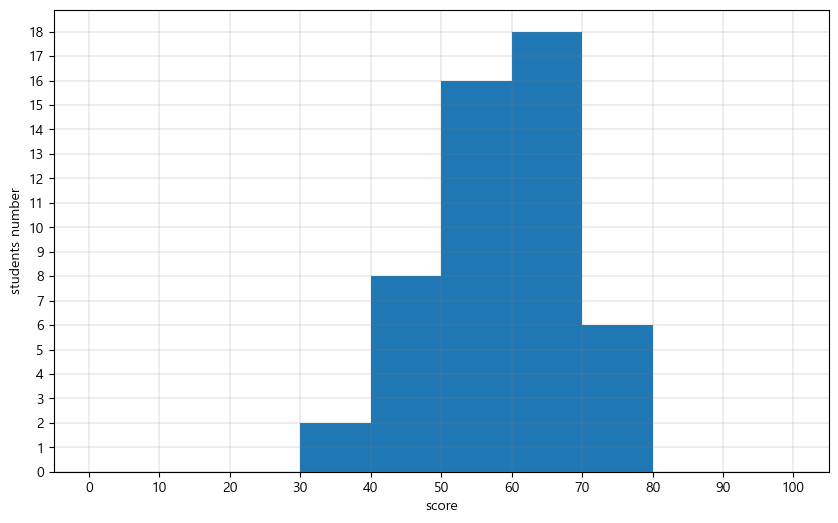

In [50]:
# subplots(row, cols, size) -> 2행, 1열 subplots(2,1,figsize=(10,8))

fig, ax = plt.subplots(figsize=(10,6))
bins,edges, patches = ax.hist(eng_scores, bins=10, range=(0,100))

# bins: 각 구간의 도수 합
# edges: 구간 경계값
# patches: 실제로 그려진 막대객체의 리스트 -> 막대별로 꾸밀 때 활용

ax.set_xlabel('score')
ax.set_ylabel('students number')
ax.set_xticks(np.linspace(0, 100, 11))
ax.set_yticks(np.arange(0, freq.max()+1));
ax.grid(True, color='gray',linewidth=0.2)

TypeError: 'bool' object is not callable

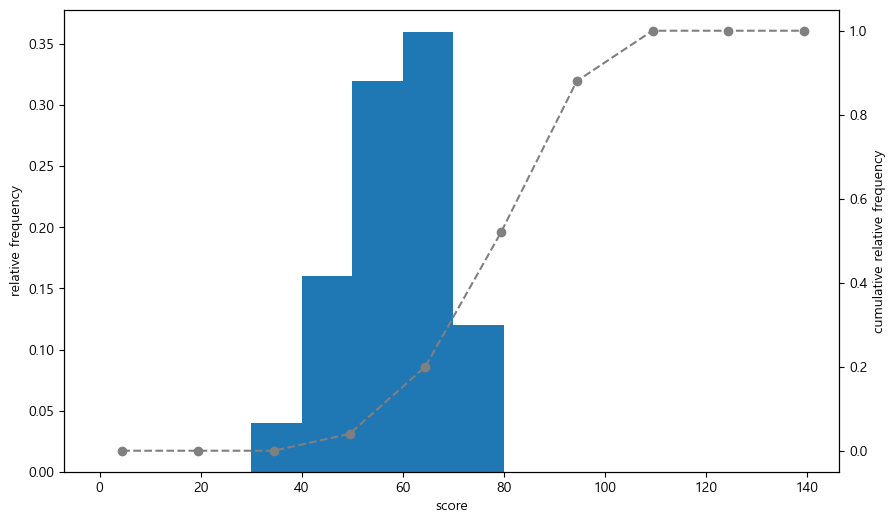

In [57]:
fig, ax1 = plt.subplots(figsize=(10,6))
ax2 = ax1.twinx() # y축의 스케일이 다른 그래프를 ax1과 동일한 영역에 생성

weights = np.ones_like(eng_scores) / len(eng_scores)
bins, edge, patches = ax1.hist(
    eng_scores,
    bins=10,
    range=(0,100),
    weights=weights
)

ax2.plot(
    eng_class_value,
    eng_cum_rel,
    ls="--",
    marker='o',
    color='gray'
)

ax1.set_xlabel('score')
ax1.set_ylabel('relative frequency')
ax2.set_ylabel('cumulative relative frequency')
ax1.set_xticks(np.little_endian(0, 100, 10+1));

### 1.5.3 상자그림
- 데이터의 산포도를 표현하는 그림 
- 데이터의 분포와 중앙값, 이상값을 동시에 시각적으로 파악 가능 
- 활용 예시
    - 시험점수 비교: 반별/과목별 분포 비교
    - 매출/소득 데이터: 이상치(대형 거래) 확인
    - 모델 성능 비교: 여러 실헝 결과의 분포 비교
- 구성
    - 상자: Q1 ~ Q3
    - 수염: (Q1 - 1.5*IQR) ~ (Q3 + 1.5*IQR) 사이의 구간 
    - 이상치: 수염에서 벗어난 값

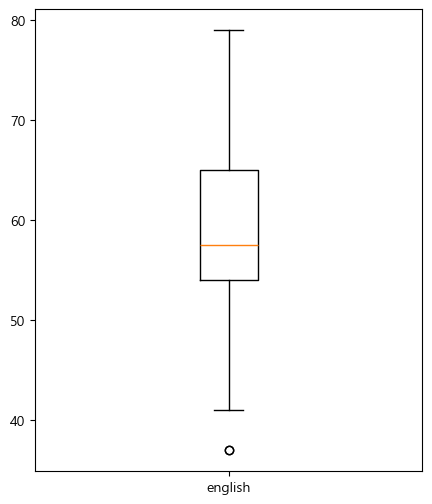

In [59]:
fig, ax = plt.subplots(figsize=(5,6))

ax.boxplot(eng_scores, tick_labels=['english']);

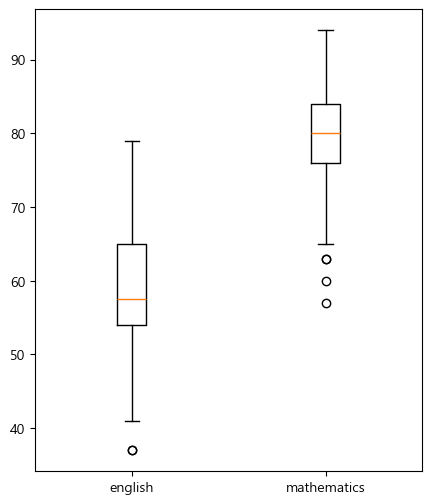

In [61]:
fig, ax = plt.subplots(figsize=(5,6))

ax.boxplot(df, tick_labels=['english', 'mathematics']);

## 2.2 공분산 (Covariance)

- 두 특성이 같이 움직이는 방향과 정도를 보는 지표 
- 두 변수가 평균을 기준으로 함께 증가하거나 감소하는지를 나타내는 지표 
- 공분산 값
    - 양수: x가 커질 때 y도 커지는 경향 (선형적인 관계)
    - 음수: x가 커질 때 y는 작아지는 경향 (선형적인 관계)
    - 0(또는 0근처): 선형적인 관계가 거의 없음 
    

In [62]:
import copy

df_copy = copy.deepcopy(df)

In [66]:
df_copy['english deviation'] = df_copy['english'] - df_copy['english'].mean()
df_copy['math deviation'] = df_copy['mathematics'] - df_copy['mathematics'].mean()
df_copy['product of deviations'] = df_copy['english deviation'] * df_copy['math deviation']

cov = df_copy['product of deviations'].mean()

In [67]:
cov_mat = np.cov(eng_scores, df_copy['mathematics'], ddof=1)
cov_mat

array([[96.03632653, 59.67918367],
       [59.67918367, 70.80163265]])

In [68]:
df.cov()

,english,mathematics
english,96.036327,59.679184
mathematics,59.679184,70.801633


## 2.3 상관계수

- 공분산: 상관관계를 확인하려는 두 특성이 같은 단위를 갖고있을 때 활용
- 상관계수: 
    - 특성끼리 단위가 다를 경우 상관관계를 확인 시 활용
    - 단위에 의존하지 않는 상관을 나타내는 지표
    - -1 ~ 1사이의 값을 가짐
        - -1에 가까움: 음의 관계가 강함
        - 1에 가까움: 양의 관계가 강함
        - 0에 가깝거나 0: 상관이 거의 없음 (두 특성이 서로에게 영향을 미치지 않음)

In [72]:
display(np.corrcoef(eng_scores, df['mathematics']))

df_copy[['english', 'mathematics']].corr()

array([[1.        , 0.72374149],
       [0.72374149, 1.        ]])

,english,mathematics
english,1.000000,0.723741
mathematics,0.723741,1.000000


# 2.4 2차원 데이터 시각화
- 두 연속형 변수의 값을 좌표평면에 점으로 찍어, 변수 간 관계(패턴, 방향, 이상치)를 보여주는 그래프 
- 관계의 방향
    - 우상향↗️: 양의관계
    - 우하향↘️: 음의 관계
    - 무작위: 관계 없음 (비선형)
- 관계의 강도
    - 점들이 선에 가깝게 몰림: 강함
    - 점들에 선에서 멀리 흩어져있음(선형이 보이지 않음): 약함 
- 활용 예시
    - 두 수치형 변수의 관계 탐색할 때 
    - 회귀분석 전 선형성/이상치 확인 

In [74]:
import matplotlib.pyplot as plt

eng_scores = df['english']
math_scores= df['mathematics']

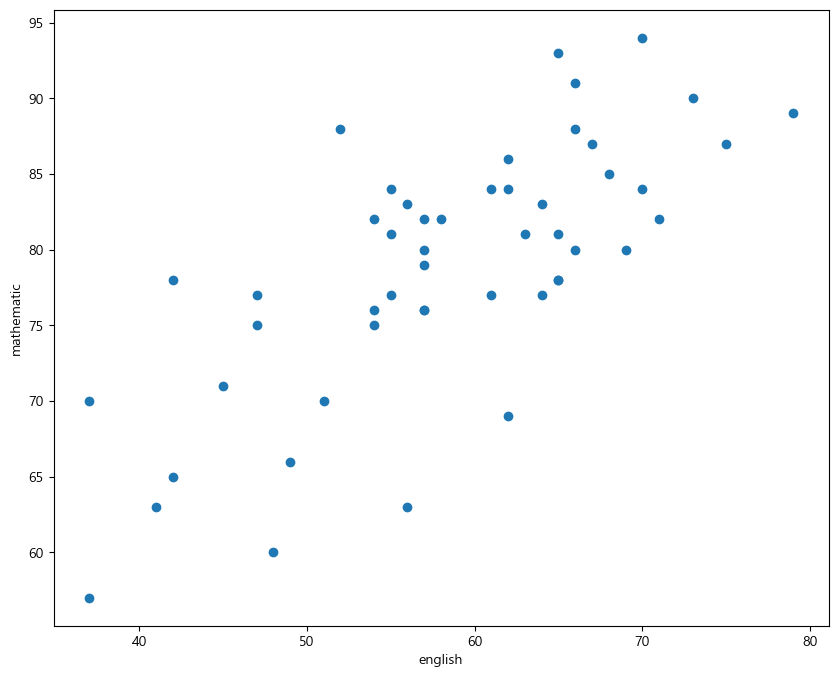

In [75]:
fig, ax = plt.subplots(figsize=(10,8))

plt.scatter(eng_scores, math_scores)

ax.set_xlabel('english')
ax.set_ylabel('mathematic');

### 2.4.2 회귀직선
- 산점도에서 보이던 점들의 경향을 하나의 직선으로 요약해줌 
- 두 특성 사이의 관계를 잘 나타내주는 직선
- `y = b_0x + b_1`


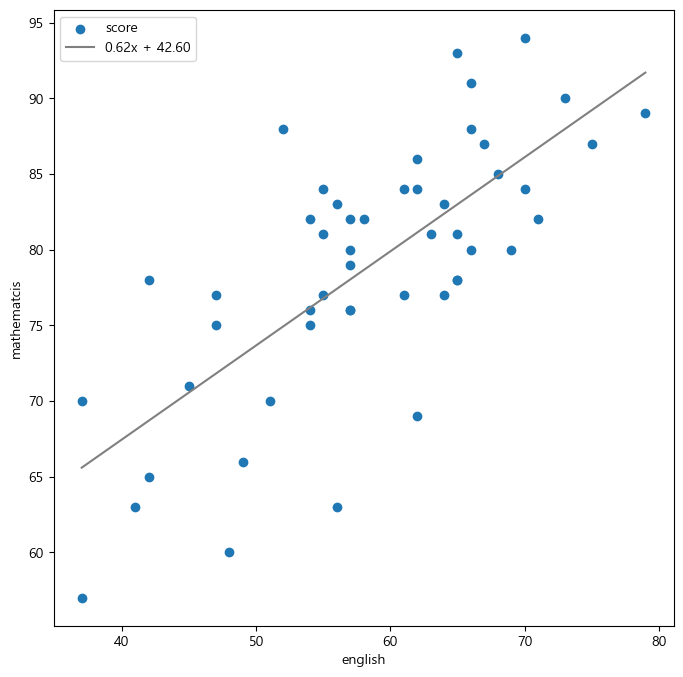

In [84]:
poly_fit = np.polyfit(eng_scores, math_scores, 1)

poly_1d = np.poly1d(poly_fit)

poly_1d(80) # 영어가 80점일 때 예측되는 수학점수

xs = np.linspace(eng_scores.min(), eng_scores.max())

ys = poly_1d(xs)

fig, ax = plt.subplots(figsize=(8,8))

ax.scatter(eng_scores, math_scores, label='score')
ax.plot(xs,ys, color='gray', label=f'{poly_fit[0]:.2f}x + {poly_fit[1]:.2f}')

ax.set_xlabel('english')
ax.set_ylabel('mathematcis')
ax.legend(loc='upper left');

# 2.4.3 히트맵
- 숫자를 색의 강도로 바꿔서 패턴을 한눈에 보게해주는 시각화 
- 행·열로 구성된 수치 데이터를 색상으로 표현해 값의 크기와 패턴을 직관적으로 보여줌 
- 진한 영역일수록 데이터가 많이 분포
- cmap: https://matplotlib.org/stable/users/explain/colors/colormaps.html

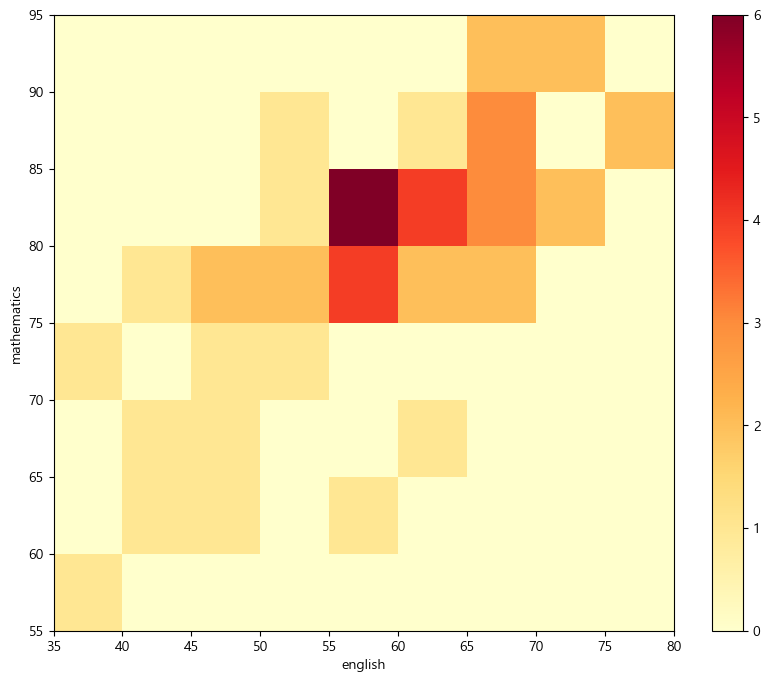

In [93]:
fig, ax = plt.subplots(figsize=(10,8))

c = ax.hist2d(
    eng_scores,
    math_scores,
    bins=[9,8],
    range=[(35,80), (55,95)],
    cmap='YlOrRd'
)

c
# c: (H, xedges, yedges, image)
# c[0]: 2차원 도수 행렬 (shape: ybins, xbins)
# c[1]: xedges, 영어 점수 구간 경계
# c[2]: yedges, 수학 점수 구간 경계
# c[3]: heatmap 객체로 실제로 그려진 컬러 이미지 객체, 컬러바를 붙일 때 사용

ax.set_xlabel('english')
ax.set_ylabel('mathematics')

ax.set_xticks(c[1])
ax.set_yticks(c[2]);

fig.colorbar(c[3], ax=ax)
